# 3. TOP 20 MOMENTUM - ROBUSTNESS BATTERY & VALIDATION GATE
Rules frozen in notebooks 01-02 (**nothing is re-tuned here**). Battery: 1. Out-of-sample + hard limit. 2. Walk-forward (fixed rules, 3y/1y). 3. Block bootstrap of the daily returns.
4. **Monkey test**: same filters, calendar, costs and stops, but the Top N is picked AT RANDOM among the eligible names. 5. Stress: slippage, best year, best names, crisis years, tails.
6. Edge decay. 7. Final gate.
### HONESTY NOTES
The OOS here is the only untouched data: if this gate fails, the variant is rejected, we do not go back to optimise.

In [1]:
from t20_tools import *
from scipy import stats
VARIANT = "t20_sp500_v1"
S = setup(VARIANT)
eng, P, rules, panel, TH, reg = S.eng, S.P, S.rules, S.panel, S.TH, S.reg
check, OOS, CAP, LIMIT, N = reg.check, S.OOS, S.CAP, S.LIMIT, S.P["top_n"]
full = eng.run_backtest(panel, **rules); ret, trades = full["ret"], full["trades"]; bh = eng.benchmark_ret(panel, ret)
oos, isr = ret[ret.index >= OOS], ret[ret.index < OOS]; m_o, m_i, b_o = eng.perf(oos), eng.perf(isr), eng.perf(bh[bh.index >= OOS])
print(f"Full {ret.index[0]:%Y-%m-%d} -> {ret.index[-1]:%Y-%m-%d} | OOS from {OOS:%Y-%m-%d}")

Data OK: 500 tickers + SPY, last bar 2026-11-09, membership yes
Variant T20M.sp500.stocks.v1 | Top 20 | momentum 63 d | first_wednesday | next_open | slip 5.0 bps/side
Panel: 500 tickers, 2003-01-02 -> 2026-11-09, OOS from 2019-01-01
Full 2003-10-20 -> 2026-11-09 | OOS from 2019-01-01


## 2. OUT-OF-SAMPLE PERFORMANCE & HARD LIMIT

            IS    OOS  SPY OOS
cagr     0.097  0.120    0.168
vol      0.151  0.221    0.192
sharpe   0.687  0.626    0.904
max_dd  -0.195 -0.299   -0.337
calmar   0.498  0.402    0.498
total    3.068  1.436    2.375
years   15.183  7.837    7.837
OOS trades 989 PF 1.59 win 49% payoff 1.66 | monthly t 1.78
   [PASS] Sharpe >= 0.4  ->  0.63
   [PASS] Profit Factor >= 1.3  ->  1.59
   [FAIL] Monthly t-stat >= 2  ->  1.78
   [FAIL] OOS Sharpe >= SPY OOS Sharpe  ->  0.63 vs 0.90
   [PASS] OOS max drawdown respects the hard limit (full allocation)  ->  -29.9% vs -30%; fraction that fits 100%


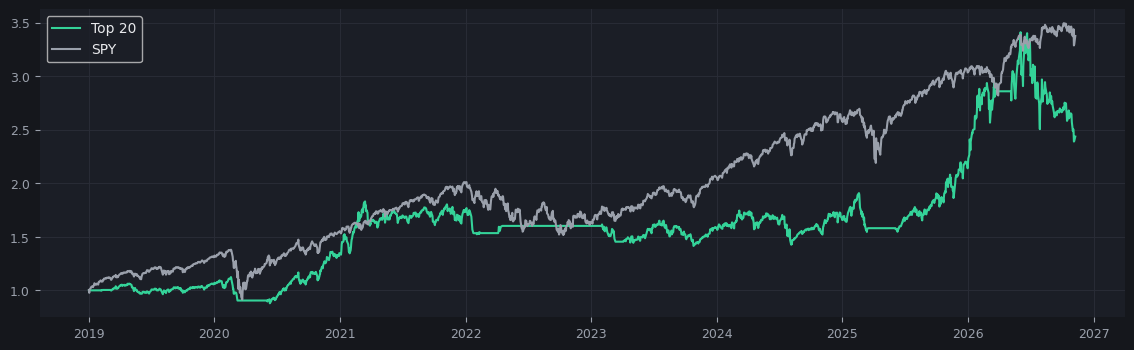

In [2]:
to = trades[(trades.reason != "open") & (trades.entry_time >= OOS)]; ts = eng.trade_stats(to); t_o = eng.tstat(eng.monthly(oos))
print(pd.DataFrame({"IS": m_i, "OOS": m_o, "SPY OOS": b_o}).round(3).to_string()); print(f"OOS trades {ts['n']} PF {ts['pf']:.2f} win {ts['win_pct']:.0f}% payoff {ts['payoff']:.2f} | monthly t {t_o:.2f}")
frac = eng.fraction_for_limit(oos, LIMIT)
check("2. OOS", f"Sharpe >= {TH['SHARPE_OOS_MIN']:g}", m_o["sharpe"] >= TH["SHARPE_OOS_MIN"], f"{m_o['sharpe']:.2f}")
check("2. OOS", f"Profit Factor >= {TH['PF_MIN']:g}", ts["pf"] >= TH["PF_MIN"], f"{ts['pf']:.2f}")
check("2. OOS", f"Monthly t-stat >= {TH['T_MIN']:g}", t_o >= TH["T_MIN"], f"{t_o:.2f}")
check("2. OOS", "OOS Sharpe >= SPY OOS Sharpe", m_o["sharpe"] >= b_o["sharpe"], f"{m_o['sharpe']:.2f} vs {b_o['sharpe']:.2f}")
check("2. OOS", "OOS max drawdown respects the hard limit (full allocation)", m_o["max_dd"] >= -LIMIT, f"{100 * m_o['max_dd']:.1f}% vs -{LIMIT:.0%}; fraction that fits {frac:.0%}")
f, a = fig(figsize=(14, 4)); a.plot((1 + oos).cumprod(), color=GREEN, label="Top 20"); a.plot((1 + bh[bh.index >= OOS]).cumprod(), color=SUB, label="SPY"); a.legend(facecolor=PANEL, labelcolor=TXT); plt.show()

## 3. WALK-FORWARD (FIXED RULES: 3Y IS / 1Y OOS)

In [3]:
wf = eng.walk_forward(ret); print(wf.round(3).to_string(index=False))
pos_w = (wf["oos_ret"] > 0).mean(); med_ratio = wf["oos_sharpe"].median()
check("3. Walk-forward", "Share of positive OOS years >= 70%", pos_w >= .7, f"{pos_w:.0%} of {len(wf)}")
check("3. Walk-forward", "Median OOS-year Sharpe >= 0.4", med_ratio >= .4, f"{med_ratio:.2f}")
check("3. Walk-forward", "No OOS year loses more than the hard limit", (wf["oos_mdd"] >= -LIMIT).all(), f"worst {100 * wf['oos_mdd'].min():.1f}%")

 oos_year  is_sharpe  oos_sharpe  oos_ret  oos_mdd
     2006      0.739       0.415    0.046   -0.145
     2007      0.772       0.994    0.146   -0.088
     2008      0.659         NaN    0.000    0.000
     2009      0.591       0.904    0.192   -0.137
     2010      0.753       0.187    0.018   -0.181
     2011      0.463      -0.095   -0.025   -0.136
     2012      0.389       1.064    0.182   -0.134
     2013      0.395       2.358    0.448   -0.062
     2014      1.142       0.361    0.040   -0.080
     2015      1.309      -0.708   -0.106   -0.189
     2016      0.749       2.207    0.361   -0.069
     2017      0.631       1.120    0.151   -0.069
     2018      0.871      -0.305   -0.061   -0.143
     2019      0.950       0.559    0.059   -0.093
     2020      0.398       1.229    0.271   -0.218
     2021      0.550       1.182    0.288   -0.133
     2022      1.034      -0.934   -0.076   -0.138
     2023      0.820       0.008   -0.010   -0.143
     2024      0.407       0.32

'PASS'

## 4. BLOCK BOOTSTRAP (5,000 SIMULATIONS, 21-DAY BLOCKS)

In [4]:
mc = eng.block_bootstrap(ret, n=5000); q = mc.quantile([.05, .5, .95]).round(3); print(q.to_string())
check("4. Monte Carlo", "5th percentile CAGR > 0", mc["cagr"].quantile(.05) > 0, f"{100 * mc['cagr'].quantile(.05):.1f}%")
check("4. Monte Carlo", "95th percentile max drawdown within 1.5 x the hard limit", mc["max_dd"].quantile(.05) >= -1.5 * LIMIT, f"{100 * mc['max_dd'].quantile(.05):.1f}%")
check("4. Monte Carlo", "5th percentile Sharpe > 0.2", mc["sharpe"].quantile(.05) > .2, f"{mc['sharpe'].quantile(.05):.2f}")

       cagr  max_dd  sharpe
0.05  0.047  -0.537   0.348
0.50  0.109  -0.361   0.674
0.95  0.173  -0.254   0.997
   [PASS] 5th percentile CAGR > 0  ->  4.7%
   [FAIL] 95th percentile max drawdown within 1.5 x the hard limit  ->  -53.7%
   [PASS] 5th percentile Sharpe > 0.2  ->  0.35


'PASS'

## 5. MONKEY TEST
`N_MONKEY` runs of the same system with a random Top N among the eligible names (so filters, stops, cash periods and costs are identical). If the ranking has no edge, the real result sits inside the cloud.

Real Sharpe full 0.65 vs monkeys 0.60 (p 0.223) | OOS 0.63 vs 0.52 (p 0.196) | CAGR 10.5% vs 6.7%
   [FAIL] Full-period Sharpe beats random Top N (p < 0.05)  ->  p 0.223
   [FAIL] OOS Sharpe beats random Top N (p < 0.05)  ->  p 0.196


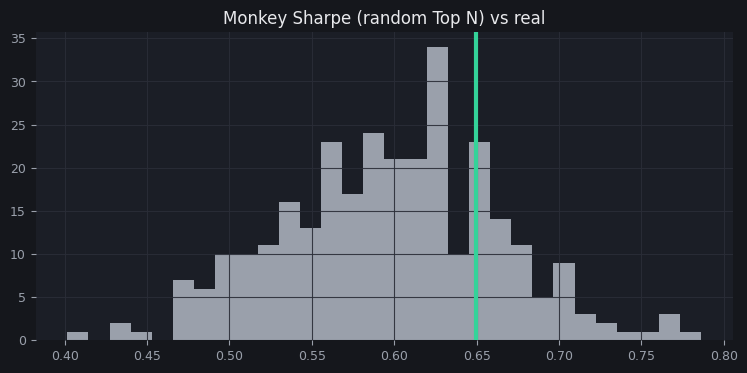

In [5]:
rng = np.random.default_rng(7); rows = []
for _ in range(TH["N_MONKEY"]):
    r = eng.run_backtest(panel, **rules, selector=eng.random_selector, rng=rng)["ret"]; rows.append(dict(full=eng.perf(r)["sharpe"], oos=eng.perf(r[r.index >= OOS])["sharpe"], cagr=eng.perf(r)["cagr"]))
mk = pd.DataFrame(rows); p_full = (1 + (mk["full"] >= eng.perf(ret)["sharpe"]).sum()) / (len(mk) + 1); p_oos = (1 + (mk["oos"] >= m_o["sharpe"]).sum()) / (len(mk) + 1)
print(f"Real Sharpe full {eng.perf(ret)['sharpe']:.2f} vs monkeys {mk['full'].mean():.2f} (p {p_full:.3f}) | OOS {m_o['sharpe']:.2f} vs {mk['oos'].mean():.2f} (p {p_oos:.3f}) | CAGR {100 * eng.perf(ret)['cagr']:.1f}% vs {100 * mk['cagr'].mean():.1f}%")
check("5. Monkey", f"Full-period Sharpe beats random Top N (p < {TH['ALPHA']:g})", p_full < TH["ALPHA"], f"p {p_full:.3f}")
check("5. Monkey", f"OOS Sharpe beats random Top N (p < {TH['ALPHA']:g})", p_oos < TH["ALPHA"], f"p {p_oos:.3f}")
f, a = fig(figsize=(9, 4)); a.hist(mk["full"], bins=30, color=SUB); a.axvline(eng.perf(ret)["sharpe"], color=GREEN, lw=3); a.set_title("Monkey Sharpe (random Top N) vs real"); plt.show()

## 6. STRESS: COSTS, BEST YEAR, BEST NAMES, CRISES, TAILS

In [6]:
sl = {b: eng.perf(eng.run_backtest(panel, **{**rules, "slip_bps_per_side": b})["ret"]) for b in (10, 20, 40)}
check("6. Stress", "Sharpe >= 0.4 at 20 bps per side", sl[20]["sharpe"] >= .4, f"{sl[20]['sharpe']:.2f}")
yrs = ret.groupby(ret.index.year).apply(lambda r: (1 + r).prod() - 1); best = yrs.idxmax(); r_nb = ret[ret.index.year != best]
check("6. Stress", "Sharpe >= 0.4 without the best year", eng.perf(r_nb)["sharpe"] >= .4, f"best {best} ({100 * yrs.max():.0f}%), Sharpe {eng.perf(r_nb)['sharpe']:.2f}")
tt = trades[trades.reason != "open"].assign(usd_pnl=lambda d: d["usd"] * d["pnl"]); top5 = tt.groupby("ticker")["usd_pnl"].sum().nlargest(5).index.tolist()
import copy; P2 = copy.copy(panel); P2.member = panel.member.copy(); P2.member[:, [panel.tickers.index(k) for k in top5]] = False
r5 = eng.run_backtest(P2, **rules)["ret"]
check("6. Stress", "Sharpe >= 0.4 excluding the 5 most profitable tickers (windfall)", eng.perf(r5)["sharpe"] >= .4, f"excluded {top5}: Sharpe {eng.perf(r5)['sharpe']:.2f}")
crisis = {"2008": (ret.index.year == 2008), "2020 Feb-Apr": (ret.index >= "2020-02-15") & (ret.index <= "2020-04-30"), "2022": (ret.index.year == 2022)}
ct = pd.DataFrame({k: {"strategy": (1 + ret[m]).prod() - 1, "SPY": (1 + bh[m]).prod() - 1, "max_dd": eng.drawdown(ret[m]).min() if m.sum() else np.nan} for k, m in crisis.items()}).T; print(ct.round(3).to_string())
check("6. Stress", "Beats SPY in every crisis window present in the data", bool((ct["strategy"] > ct["SPY"]).all()), f"{ct['strategy'].round(3).to_dict()}")
w = ret.nsmallest(20).mean(); mo = eng.monthly(ret)
check("6. Stress", "Worst month better than -15%", mo.min() > -.15, f"{100 * mo.min():.1f}% ({mo.idxmin():%Y-%m})")
check("6. Stress", "CVaR 5% of the daily returns better than -3%", ret[ret <= ret.quantile(.05)].mean() > -.03, f"{100 * ret[ret <= ret.quantile(.05)].mean():.2f}%")

   [PASS] Sharpe >= 0.4 at 20 bps per side  ->  0.55
   [PASS] Sharpe >= 0.4 without the best year  ->  best 2013 (45%), Sharpe 0.58
   [PASS] Sharpe >= 0.4 excluding the 5 most profitable tickers (windfall)  ->  excluded ['WDC', 'STX', 'MU', 'SNDK', 'NVDA']: Sharpe 0.51
              strategy    SPY  max_dd
2008             0.000 -0.368   0.000
2020 Feb-Apr    -0.185 -0.135  -0.195
2022            -0.076 -0.182  -0.138
   [FAIL] Beats SPY in every crisis window present in the data  ->  {'2008': 0.0, '2020 Feb-Apr': -0.185, '2022': -0.076}
   [FAIL] Worst month better than -15%  ->  -18.2% (2026-07)
   [PASS] CVaR 5% of the daily returns better than -3%  ->  -2.83%


'PASS'

## 7. EDGE DECAY & TEMPORAL STABILITY

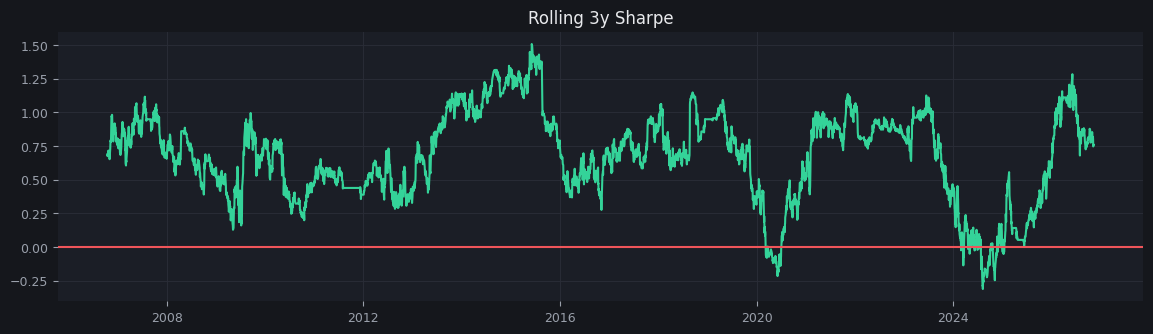

   [PASS] Second-half Sharpe >= 50% of the first half  ->  0.58 vs 0.75
   [PASS] Last rolling 3y Sharpe > 0  ->  0.76
   [PASS] Rolling-Sharpe slope per year > -0.15  ->  -0.01 / year


'PASS'

In [7]:
rs = ret.rolling(756).apply(lambda r: r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan, raw=True).dropna()
f, a = fig(figsize=(14, 3.5)); a.plot(rs, color=GREEN); a.axhline(0, color=RED); a.set_title("Rolling 3y Sharpe"); plt.show()
h = len(ret) // 2; s1, s2 = eng.perf(ret.iloc[:h])["sharpe"], eng.perf(ret.iloc[h:])["sharpe"]; sl_ = stats.linregress(np.arange(len(rs)), rs.values).slope * 252 if len(rs) > 10 else np.nan
check("7. Decay", "Second-half Sharpe >= 50% of the first half", s2 >= .5 * s1, f"{s2:.2f} vs {s1:.2f}")
check("7. Decay", "Last rolling 3y Sharpe > 0", len(rs) > 0 and rs.iloc[-1] > 0, f"{rs.iloc[-1]:.2f}" if len(rs) else "n/a")
check("7. Decay", "Rolling-Sharpe slope per year > -0.15", sl_ > -.15, f"{sl_:+.2f} / year")

## 8-9. FULL VALIDATION GATE, VERDICT

In [8]:
ESSENTIAL = [("2. OOS", "Sharpe", "OOS Sharpe too low."), ("2. OOS", "Profit Factor", "OOS PF below the minimum."), ("2. OOS", "Monthly t-stat", "OOS not significant."),
    ("2. OOS", "OOS Sharpe >= SPY", "Does not beat buy & hold OOS."), ("2. OOS", "OOS max drawdown", "OOS drawdown breaks the hard limit: scale the fraction."),
    ("3. Walk-forward", "Share of positive", "Unstable across years."), ("4. Monte Carlo", "5th percentile CAGR", "Bootstrap says it can lose money."),
    ("5. Monkey", "Full-period", "Random Top N does as well: no stock-selection edge."), ("5. Monkey", "OOS Sharpe beats", "Random Top N does as well OOS."),
    ("6. Stress", "Sharpe >= 0.4 at 20 bps", "Edge dies with 4x slippage."), ("6. Stress", "Sharpe >= 0.4 without the best", "Depends on one year."),
    ("6. Stress", "Sharpe >= 0.4 excluding", "Depends on a handful of stocks."), ("7. Decay", "Last rolling", "Edge is decaying.")]
go = gate(reg, ESSENTIAL, headline=f"| OOS Sharpe {m_o['sharpe']:.2f} (SPY {b_o['sharpe']:.2f}) | monkey p {p_oos:.3f}")
status = "VALIDATED (conditional on forward data)" if go else "NOT VALIDATED"; print(f"\nVERDICT: {status}. Next: 04_Top20_Momentum_Reconciliation.ipynb with paper trading, only if validated.")

DECISION: STOP  (9 PASS / 4 FAIL / 0 SKIP of 13 essential)  | OOS Sharpe 0.63 (SPY 0.90) | monkey p 0.196

2. OOS
   [PASS] Sharpe >= 0.4  ->  0.63
   [PASS] Profit Factor >= 1.3  ->  1.59
   [FAIL] Monthly t-stat >= 2  ->  1.78
   [FAIL] OOS Sharpe >= SPY OOS Sharpe  ->  0.63 vs 0.90
   [PASS] OOS max drawdown respects the hard limit (full allocation)  ->  -29.9% vs -30%; fraction that fits 100%

3. Walk-forward
   [PASS] Share of positive OOS years >= 70%  ->  71% of 21

4. Monte Carlo
   [PASS] 5th percentile CAGR > 0  ->  4.7%

5. Monkey
   [FAIL] Full-period Sharpe beats random Top N (p < 0.05)  ->  p 0.223
   [FAIL] OOS Sharpe beats random Top N (p < 0.05)  ->  p 0.196

6. Stress
   [PASS] Sharpe >= 0.4 at 20 bps per side  ->  0.55
   [PASS] Sharpe >= 0.4 without the best year  ->  best 2013 (45%), Sharpe 0.58
   [PASS] Sharpe >= 0.4 excluding the 5 most profitable tickers (windfall)  ->  excluded ['WDC', 'STX', 'MU', 'SNDK', 'NVDA']: Sharpe 0.51

7. Decay
   [PASS] Last rolling 

## 10. SAVE

In [9]:
S.vc.save_json(S.cfg, "03_robustness.json", dict(variant=S.cfg["id"], validated=bool(go), oos={k: float(v) for k, v in m_o.items()}, monkey_p_full=p_full, monkey_p_oos=p_oos,
    fraction_for_limit=frac, checks=reg.df().to_dict("records")))

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Top20_Momentum/runs/t20_sp500_v1/03_robustness.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Top20_Momentum/runs/t20_sp500_v1/03_robustness.json')